# Calculating elastic modulus

Calculation of elastic modulus used in the Bouligand composite manuscript analysis. The Excel workbook here contains generated example data.

## Modulus calculation

$$E_{\mathrm{chord}}=\frac{\sigma(\varepsilon_2)-\sigma(\varepsilon_1)}{\varepsilon_2-\varepsilon_1},\qquad \sigma=E_{\mathrm{fit}}\varepsilon+c.$$

The endpoints use interpolation. Specimen variation is reported as the sample standard deviation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#233744", "text.color": "#233744",
    "axes.edgecolor": "#9aabb2", "figure.facecolor": "white",
    "savefig.facecolor": "white", "svg.fonttype": "none",
})
colors = ["#236b73", "#bb7639", "#5d6eaa"]
Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

from scipy.stats import linregress

In [2]:
workbook = Path("inputs/composite_example.xlsx")
measurements = pd.read_excel(workbook, sheet_name="Measurements")
dimensions = pd.read_excel(workbook, sheet_name="Dimensions", usecols="A:G")
dimensions = dimensions.set_index("specimen", verify_integrity=True)

curves, cleaning = {}, []
for specimen, raw in measurements.groupby("specimen", sort=False):
    d = dimensions.loc[specimen]
    if set(raw["test"]) != {d["test"]}:
        raise ValueError(f"Test labels disagree for {specimen}")
    if min(d["width_mm"], d["thickness_mm"], d["length_mm"]) <= 0:
        raise ValueError(f"Invalid dimensions for {specimen}")
    pair = raw[["displacement_mm", "force_N"]].apply(pd.to_numeric, errors="coerce")
    pair = pair.replace([np.inf, -np.inf], np.nan).dropna()
    displacement, force = pair.to_numpy().T
    width, thickness, length = d[["width_mm", "thickness_mm", "length_mm"]]
    if d["test"] == "flexural":
        strain = 6 * displacement * thickness / length**2
        stress = 3 * force * length / (2 * width * thickness**2)
    elif d["test"] == "tensile":
        strain = displacement / length
        stress = force / (width * thickness)
    else:
        raise ValueError(f"Unknown test: {d['test']}")
    if len(strain) < 3 or np.any(np.diff(strain) <= 0):
        raise ValueError(f"Expected an increasing loading curve for {specimen}")
    curves[specimen] = pd.DataFrame({"strain": strain, "stress_MPa": stress})
    cleaning.append({"specimen": specimen, "retained": len(pair), "missing_pairs": len(raw) - len(pair)})

In [3]:
def elastic_properties(curve, e1, e2):
    strain, stress = curve[["strain", "stress_MPa"]].to_numpy().T
    peak = int(np.argmax(stress))
    if not strain[0] <= e1 < e2 <= strain[peak]:
        raise ValueError("The modulus interval must lie on the pre-peak loading branch")
    use = (strain >= e1) & (strain <= e2)
    if use.sum() < 3:
        raise ValueError("At least three points are needed in the fitting interval")
    ends = np.interp([e1, e2], strain[:peak + 1], stress[:peak + 1])
    fit = linregress(strain[use], stress[use])
    return (ends[1] - ends[0]) / (e2 - e1), fit

fits, rows = {}, []
for name, curve in curves.items():
    d = dimensions.loc[name]
    chord, fit = elastic_properties(curve, d["strain_low"], d["strain_high"])
    fits[name] = fit
    rows.append({"specimen": name, "test": d["test"], "chord_GPa": chord / 1000,
                 "regression_GPa": fit.slope / 1000, "fit_R2": fit.rvalue**2})
properties = pd.DataFrame(rows)
summary = properties.groupby("test")["chord_GPa"].agg(n="count", mean="mean", sd="std")
properties.to_csv("results/elastic_modulus.csv", index=False)
summary.to_csv("results/modulus_summary.csv")
display(properties.round({"chord_GPa": 3, "regression_GPa": 3, "fit_R2": 4}))

,specimen,test,chord_GPa,regression_GPa,fit_R2
0,F1,flexural,4.560,4.560,1.0
1,F2,flexural,4.800,4.800,1.0
2,F3,flexural,5.088,5.088,1.0
3,T1,tensile,5.890,5.890,1.0
4,T2,tensile,6.200,6.200,1.0
5,T3,tensile,6.572,6.572,1.0


## Elastic response

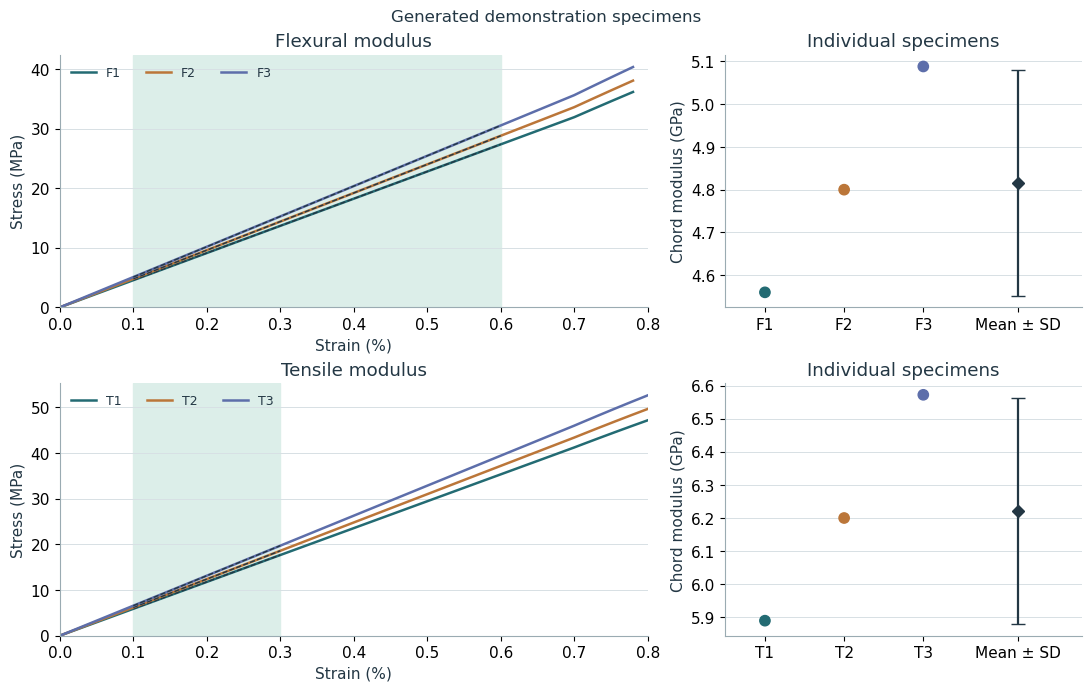

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(10.8, 6.8), layout="constrained",
                       gridspec_kw={"width_ratios": [1.65, 1]})
for axes, test, title in zip(ax, ["flexural", "tensile"], ["Flexural modulus", "Tensile modulus"]):
    left, right = axes
    names = list(dimensions.index[dimensions["test"] == test])
    d0 = dimensions.loc[names[0]]
    left.axvspan(100 * d0["strain_low"], 100 * d0["strain_high"], color="#dceee9", zorder=0)
    for name, color in zip(names, colors):
        curve, fit = curves[name], fits[name]
        visible = curve["strain"] <= 0.008
        left.plot(100 * curve.loc[visible, "strain"], curve.loc[visible, "stress_MPa"],
                  color=color, lw=1.8, label=name)
        e = dimensions.loc[name, ["strain_low", "strain_high"]].to_numpy(float)
        left.plot(100 * e, fit.slope * e + fit.intercept, color="#233744", lw=1, ls="--")
    left.set(xlabel="Strain (%)", ylabel="Stress (MPa)", title=title, xlim=(0, 0.8), ylim=(0, None))
    left.legend(frameon=False, fontsize=9, ncol=3, loc="upper left")
    values = properties.loc[properties["test"] == test, "chord_GPa"].to_numpy()
    right.scatter(np.arange(3), values, c=colors, s=55, zorder=3)
    right.errorbar(3.2, summary.loc[test, "mean"], yerr=summary.loc[test, "sd"],
                   fmt="D", ms=6, capsize=5, color="#233744", lw=1.6)
    right.set(xticks=[0, 1, 2, 3.2], xticklabels=names + ["Mean ± SD"],
              ylabel="Chord modulus (GPa)", title="Individual specimens", xlim=(-0.5, 4))
    for a in axes:
        a.grid(axis="y", color="#d7e0e4", lw=0.7)
fig.suptitle("Generated demonstration specimens", fontsize=12)
fig.savefig("figures/elastic_modulus.png", dpi=180, bbox_inches="tight")
fig.savefig("figures/elastic_modulus.svg", bbox_inches="tight")
plt.show()